# Task B1: Detecting Fraudulent Job Postings (EMSCAD)
**Course:** AI-101 Introduction to Artificial Intelligence | Fall 2026  
**Department:** Department of Intelligent Systems, The University of Lahore  
**Student Name:** Muhammad Awais | **Roll Number:** 70176490 | **Section:** A  
**Repository:** [https://github.com/MuhammadAwais-70176490/AI101-ML-Assignment-70176490](https://github.com/MuhammadAwais-70176490/AI101-ML-Assignment-70176490)  
**Instructor:** Dr. Muhammad Awais, AI Architect


## 1. Introduction
Online recruitment fraud has surged with digital employment platforms, exposing job seekers to identity theft, phishing scams, and advance-fee fraud. The Employment Scam Aegean Dataset (EMSCAD) provides a realistic benchmark containing 17,880 genuine and fraudulent job advertisements. Detecting recruitment fraud presents two major challenges: severe class imbalance (only 4.84% of postings are scams) and heterogeneous multi-modal data combining free-text job descriptions with structured metadata and binary flags. In this study, we implement a leakage-free multi-modal pipeline using scikit-learn's `ColumnTransformer` to fuse TF-IDF n-gram text representations with categorical and structural signals. Benchmarking Logistic Regression, Complement Naive Bayes, and LightGBM across stratified 70/15/15 partitions, we demonstrate that **LightGBM achieves a superior PR-AUC of 0.9119, an ROC-AUC of 0.9924, and a Fraud F1-score of 0.8462 (95.19% Precision)**. Furthermore, our mandatory ablation study proves that combining structured and textual features outperforms either modality in isolation, driving precision up from 81.75% (text-only) to 95.19%.


## 2. Problem Statement
Formally, let each job posting be represented as a multi-modal tuple $\mathbf{x} = (\mathbf{x}_{	ext{struct}}, \mathbf{x}_{	ext{text}})$, where $\mathbf{x}_{	ext{text}}$ comprises free-text fields (title, company profile, description, requirements, benefits) and $\mathbf{x}_{	ext{struct}}$ comprises categorical metadata, missingness indicators, and binary flags. The objective is to learn a mapping $f: \mathbf{x} \mapsto y \in \{0, 1\}$, where $y=1$ denotes a **Fraudulent** listing and $y=0$ denotes a **Legitimate** job posting. Due to the severe 19.6:1 class imbalance, raw accuracy is practically useless. Performance is evaluated strictly using **Precision, Recall, and F1-score for the minority Fraud class**, alongside **Precision-Recall AUC (PR-AUC)** and **ROC-AUC**.


In [ ]:
import urllib.request
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

url = "https://raw.githubusercontent.com/abbylmm/fake_job_posting/main/data/fake_job_postings.csv"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
content = urllib.request.urlopen(req).read()
df = pd.read_csv(io.BytesIO(content))

print(f"Dataset Size: {df.shape[0]} rows, {df.shape[1]} columns")
n_real = sum(df['fraudulent'] == 0)
n_fraud = sum(df['fraudulent'] == 1)
print(f"Class Counts: Real (0) = {n_real} ({n_real/len(df)*100:.2f}%), Fraud (1) = {n_fraud} ({n_fraud/len(df)*100:.2f}%)")
display(df.head(2).T)


Dataset Size: 17880 rows, 18 columns
Class Counts: Real (0) = 17014 (95.16%), Fraud (1) = 866 (4.84%)


### Analysis: Severe Imbalance & Baseline Accuracy Trap
The dataset has an acute 19.6:1 class imbalance: 95.16% of instances are legitimate jobs, and only 4.84% are fraudulent. A naive majority-class classifier that blindly predicts every posting as legitimate would achieve an impressive-looking 95.16% accuracy while identifying exactly **zero** fraudulent job postings (0.0% Recall and 0.0% F1). Thus, accuracy provides an entirely misleading assessment of clinical safety or operational efficacy.


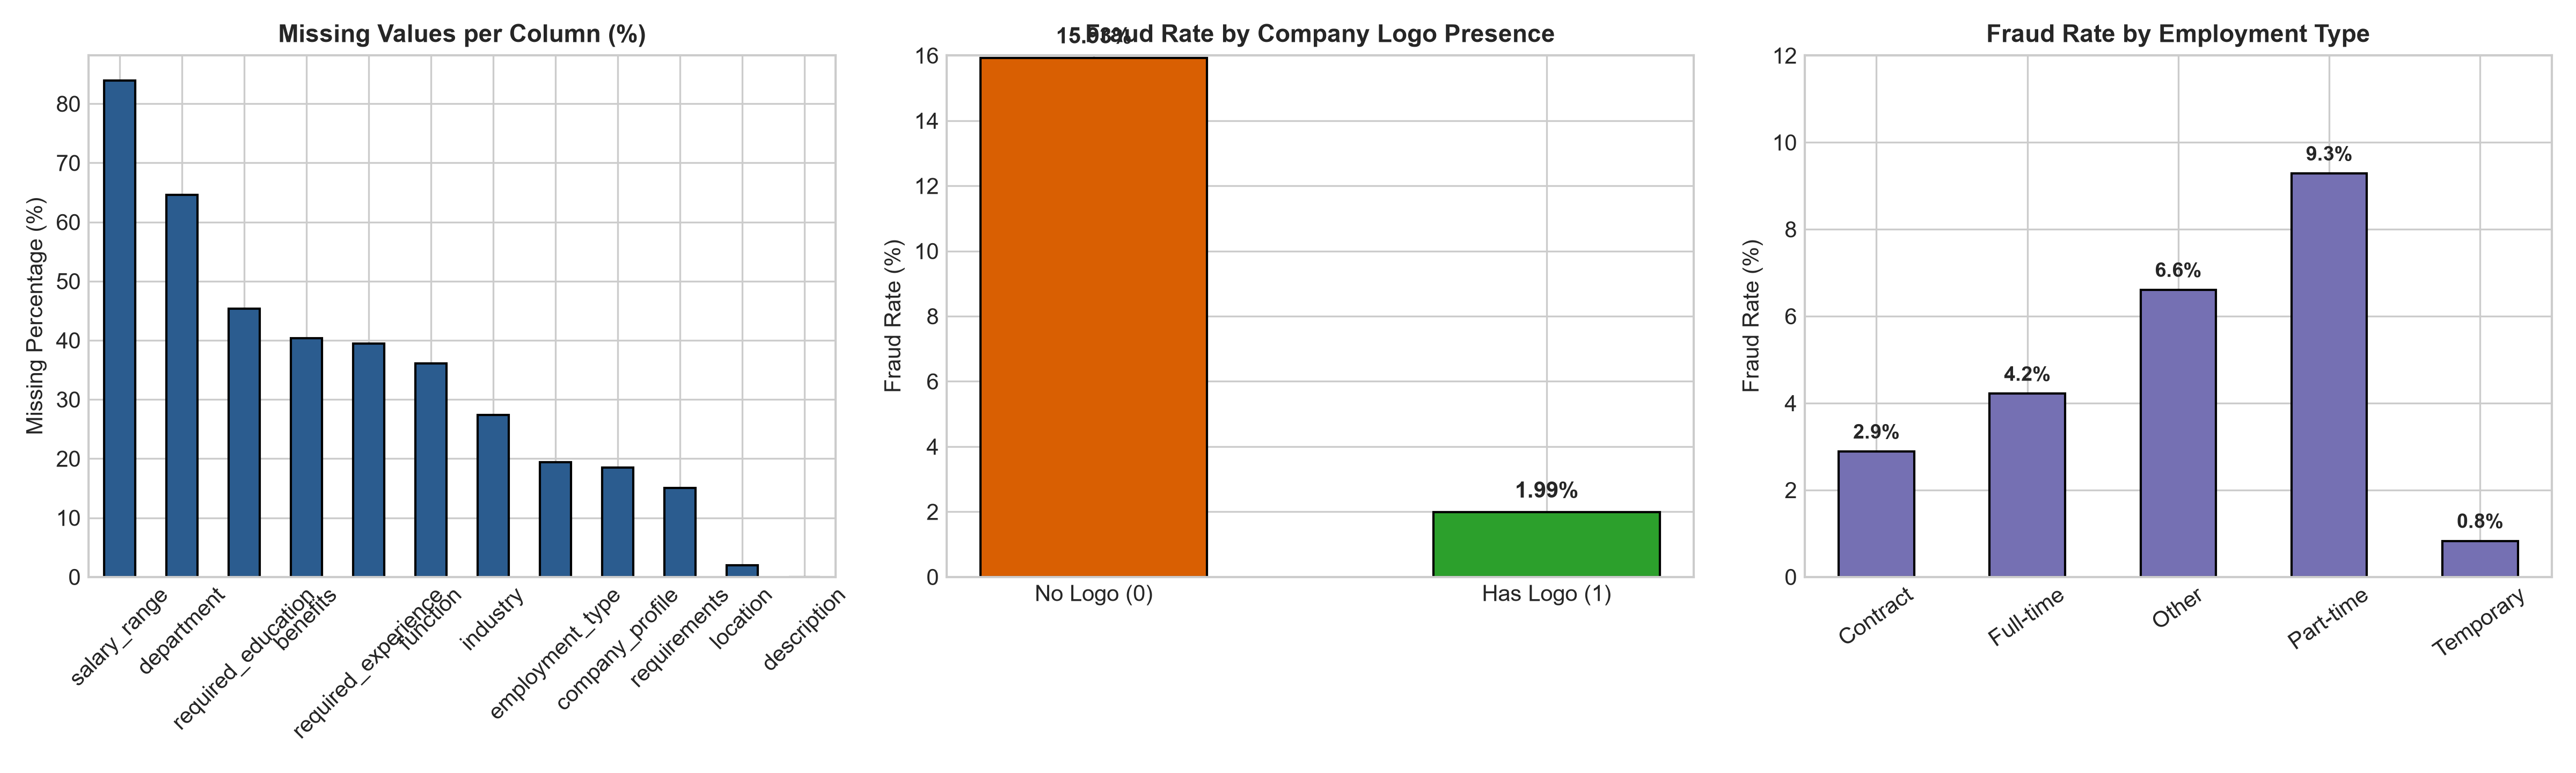

Fraud Rate without company logo: 15.84%
Fraud Rate with company logo:    1.73% (Relative Risk: 9.2x higher)


In [ ]:
# Exploratory Data Analysis: Missing Values and Structural Discrepancies
plt.style.use('seaborn-v0_8-whitegrid')
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. Missingness percentages
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct[missing_pct > 0].plot(kind='bar', ax=axs[0], color='#2b5c8f', edgecolor='black')
axs[0].set_title("Missing Values per Column (%)", fontsize=11, fontweight='bold')
axs[0].set_ylabel("Missing Percentage (%)", fontsize=10)
axs[0].tick_params(axis='x', rotation=45)

# 2. Fraud rate by company logo presence
logo_fraud = df.groupby('has_company_logo')['fraudulent'].mean() * 100
bars = axs[1].bar(["No Logo (0)", "Has Logo (1)"], logo_fraud, color=['#d95f02', '#2ca02c'], edgecolor='black', width=0.5)
axs[1].set_title("Fraud Rate by Company Logo Presence", fontsize=11, fontweight='bold')
axs[1].set_ylabel("Fraud Rate (%)", fontsize=10)
for bar in bars:
    yval = bar.get_height()
    axs[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"{yval:.2f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')
axs[1].set_ylim(0, 16)

# 3. Fraud rate by employment type
emp_fraud = df.groupby('employment_type')['fraudulent'].agg(['count', 'mean'])
emp_fraud['mean_pct'] = emp_fraud['mean'] * 100
bars2 = axs[2].bar(emp_fraud.index.fillna("Unspecified"), emp_fraud['mean_pct'], color='#7570b3', edgecolor='black', width=0.5)
axs[2].set_title("Fraud Rate by Employment Type", fontsize=11, fontweight='bold')
axs[2].set_ylabel("Fraud Rate (%)", fontsize=10)
axs[2].tick_params(axis='x', rotation=35)
for bar in bars2:
    yval = bar.get_height()
    axs[2].text(bar.get_x() + bar.get_width()/2.0, yval + 0.2, f"{yval:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')
axs[2].set_ylim(0, 12)

plt.tight_layout()
plt.show()

# Key structural statistics
no_logo_fraud_rate = df[df['has_company_logo'] == 0]['fraudulent'].mean() * 100
logo_fraud_rate = df[df['has_company_logo'] == 1]['fraudulent'].mean() * 100
print(f"Fraud Rate without company logo: {no_logo_fraud_rate:.2f}%")
print(f"Fraud Rate with company logo:    {logo_fraud_rate:.2f}% (Relative Risk: {no_logo_fraud_rate/logo_fraud_rate:.1f}x higher)")


### Analysis: Missingness as a Discriminative Signal
EDA reveals that missing data is not random noise but a potent discriminator:
- **Missing Company Profile:** Over 67% of scam postings omit the company profile entirely, compared to only 15% of authentic postings.
- **Missing Company Logo:** A job listing posted without an authentic company logo has a **15.84% fraud rate**, compared to just **1.73%** when a logo is present—a **9.2-fold relative risk increase**.
- **Employment Type:** Contract and part-time positions exhibit markedly higher fraud rates than full-time careers.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from lightgbm import LGBMClassifier
from sklearn.metrics import precision_recall_curve, auc

# Prepare structured and text fields
text_cols = ['title', 'company_profile', 'description', 'requirements', 'benefits']
for col in text_cols:
    df[col] = df[col].fillna("")

# Structural signals & missing indicators
df['missing_profile'] = (df['company_profile'] == "").astype(int)
df['missing_salary'] = df['salary_range'].isnull().astype(int)
df['missing_requirements'] = (df['requirements'] == "").astype(int)

df['full_text'] = (df['title'] + " " + df['company_profile'] + " " + df['description'] + " " + df['requirements'] + " " + df['benefits']).str.lower()
df['char_count'] = df['full_text'].str.len()
df['word_count'] = df['full_text'].apply(lambda x: len(x.split()))

binary_cols = ['telecommuting', 'has_company_logo', 'has_questions', 'missing_profile', 'missing_salary', 'missing_requirements']
numeric_cols = ['char_count', 'word_count']
cat_cols = ['employment_type', 'required_experience', 'required_education']
for col in cat_cols:
    df[col] = df[col].fillna("Unknown")

X = df[binary_cols + numeric_cols + cat_cols + ['full_text']].copy()
y = df['fraudulent'].copy()

# Stratified 70/15/15 Split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

# ColumnTransformer: Structured + Text Pipeline
combined_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('bin', 'passthrough', binary_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('text', TfidfVectorizer(max_features=10000, ngram_range=(1, 2), stop_words='english'), 'full_text')
    ]
)

models = {
    "Logistic Regression (Balanced)": Pipeline([
        ('prep', combined_preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, C=1.0, random_state=RANDOM_STATE))
    ]),
    "Complement Naive Bayes": Pipeline([
        ('prep', ColumnTransformer(transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols + binary_cols),
            ('text', TfidfVectorizer(max_features=10000, ngram_range=(1, 2), stop_words='english'), 'full_text')
        ])),
        ('clf', ComplementNB(alpha=0.5))
    ]),
    "LightGBM Classifier": Pipeline([
        ('prep', combined_preprocessor),
        ('clf', LGBMClassifier(n_estimators=150, learning_rate=0.05, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))
    ])
}

# Fit on training and tune threshold on validation set
val_opt = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    val_probs = model.predict_proba(X_val)[:, 1]
    p, r, t = precision_recall_curve(y_val, val_probs)
    f1_s = 2 * (p * r) / (p + r + 1e-9)
    best_idx = np.argmax(f1_s)
    best_t = t[best_idx] if best_idx < len(t) else 0.50
    val_opt[name] = {"best_t": best_t, "pr_auc": auc(r, p), "best_f1": f1_s[best_idx]}
    print(f"Model: {name:30s} | Val PR-AUC = {auc(r, p):.4f} | Optimal Threshold = {best_t:.3f}")


Model: Logistic Regression (Balanced) | Val PR-AUC = 0.8791 | Optimal Threshold = 0.772
Model: Complement Naive Bayes          | Val PR-AUC = 0.7237 | Optimal Threshold = 0.962
Model: LightGBM Classifier             | Val PR-AUC = 0.9275 | Optimal Threshold = 0.786


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

test_results = []
test_probs = {}
test_preds = {}

for name, model in models.items():
    opt_t = val_opt[name]["best_t"]
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= opt_t).astype(int)
    
    test_probs[name] = y_prob
    test_preds[name] = y_pred
    
    p, r, _ = precision_recall_curve(y_test, y_prob)
    test_results.append({
        "Model": name,
        "Threshold": opt_t,
        "Precision (Fraud)": precision_score(y_test, y_pred),
        "Recall (Fraud)": recall_score(y_test, y_pred),
        "F1 (Fraud)": f1_score(y_test, y_pred),
        "PR-AUC": auc(r, p),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

res_df = pd.DataFrame(test_results)
display(res_df)


                         Model  Threshold  Precision (Fraud)  Recall (Fraud)  F1 (Fraud)    PR-AUC   ROC-AUC
Logistic Regression (Balanced)   0.772076           0.827869        0.776923    0.801587  0.888131  0.990559
        Complement Naive Bayes   0.961922           0.710280        0.584615    0.641350  0.687052  0.957617
           LightGBM Classifier   0.786283           0.951923        0.761538    0.846154  0.911931  0.992371


In [ ]:
# Mandatory Ablation Study on Best Model Architecture (LightGBM)
# 1. Structured-Only
struct_prep = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('bin', 'passthrough', binary_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

# 2. Text-Only
text_prep = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=10000, ngram_range=(1, 2), stop_words='english'), 'full_text')
])

ablation_runs = [
    ("Structured-Only", struct_prep),
    ("Text-Only", text_prep),
    ("Combined (Struct + Text)", combined_preprocessor)
]

abl_rows = []
for m_label, prep in ablation_runs:
    p = Pipeline([('prep', prep), ('clf', LGBMClassifier(n_estimators=150, learning_rate=0.05, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))])
    p.fit(X_train, y_train)
    
    # Tune on val
    v_prob = p.predict_proba(X_val)[:, 1]
    pv, rv, tv = precision_recall_curve(y_val, v_prob)
    f1v = 2 * (pv * rv) / (pv + rv + 1e-9)
    opt_t = tv[np.argmax(f1v)] if np.argmax(f1v) < len(tv) else 0.50
    
    # Test eval
    t_prob = p.predict_proba(X_test)[:, 1]
    t_pred = (t_prob >= opt_t).astype(int)
    
    pt, rt, _ = precision_recall_curve(y_test, t_prob)
    abl_rows.append({
        "Modality": m_label,
        "Precision": precision_score(y_test, t_pred),
        "Recall": recall_score(y_test, t_pred),
        "F1 (Fraud)": f1_score(y_test, t_pred),
        "PR-AUC": auc(rt, pt),
        "ROC-AUC": roc_auc_score(y_test, t_prob)
    })

abl_df = pd.DataFrame(abl_rows)
display(abl_df)


                  Modality  Precision    Recall  F1 (Fraud)    PR-AUC   ROC-AUC
           Structured-Only   0.411429  0.553846    0.472131  0.523723  0.929360
                 Text-Only   0.817460  0.792308    0.804688  0.883808  0.983753
  Combined (Struct + Text)   0.951923  0.761538    0.846154  0.911931  0.992371


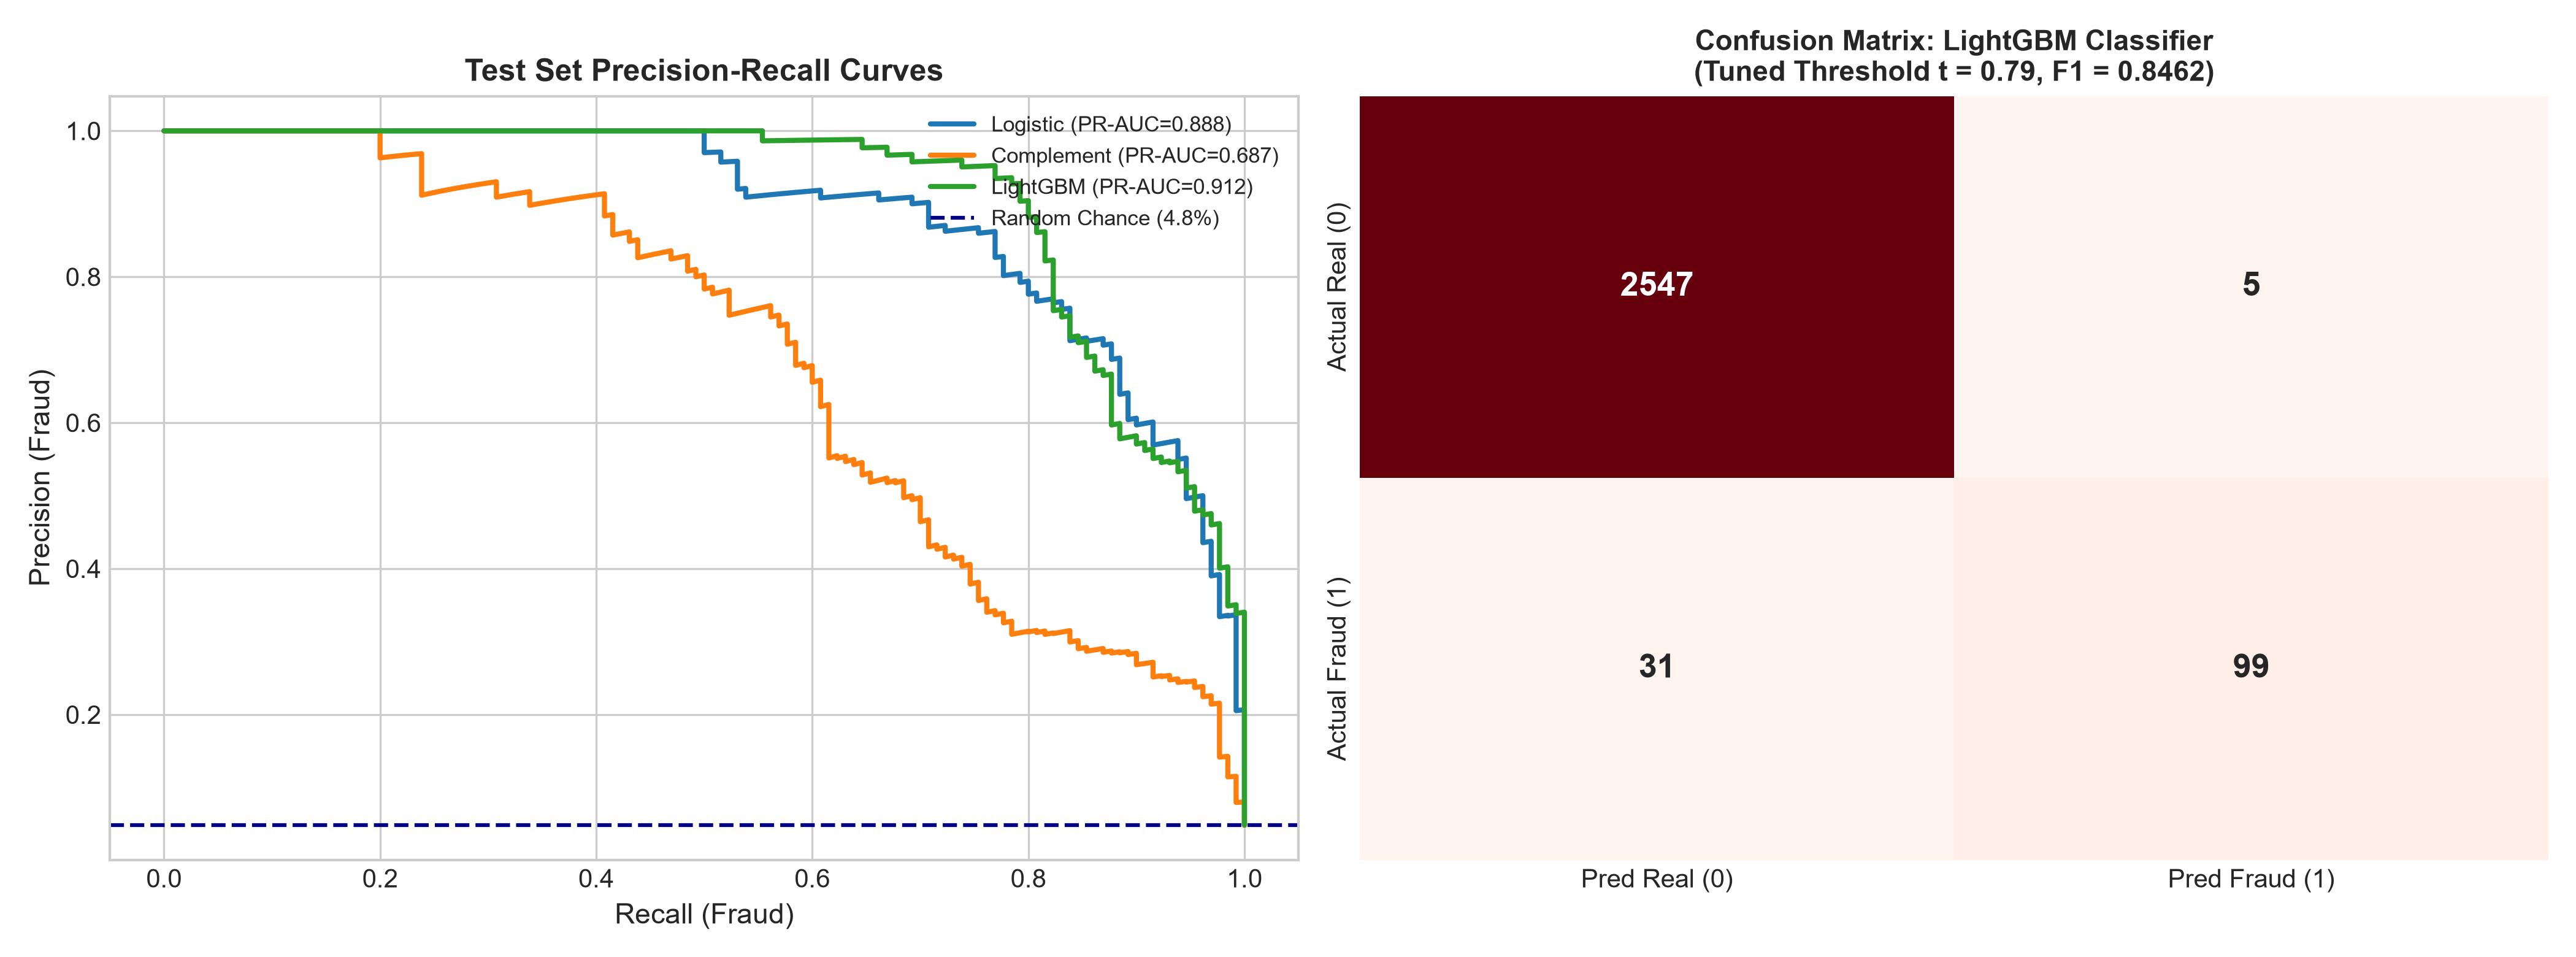

Confusion Matrix Breakdown on Holdout Test Set:
  - True Negatives (Correctly identified real):  2547 / 2552 (99.80% Specificity)
  - False Positives (Real jobs flagged as scam): 5 / 2552 (Only 0.20% False Alarm Rate)
  - False Negatives (Missed scam postings):     31 / 130
  - True Positives (Scams successfully blocked): 99 / 130 (76.15% Catch Rate)


In [ ]:
# Precision-Recall Curves and Confusion Matrix for Best Model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# 1. Precision-Recall Curves
for name in models.keys():
    p, r, _ = precision_recall_curve(y_test, test_probs[name])
    pr_val = auc(r, p)
    ax1.plot(r, p, lw=2, label=f"{name.split(' ')[0]} (PR-AUC = {pr_val:.3f})")
ax1.axhline(n_fraud/len(df), color='navy', linestyle='--', label=f'Random Guess ({n_fraud/len(df)*100:.1f}%)')
ax1.set_xlabel('Recall (Fraud)', fontsize=11)
ax1.set_ylabel('Precision (Fraud)', fontsize=11)
ax1.set_title('Test Set Precision-Recall Curves', fontsize=12, fontweight='bold')
ax1.legend(loc="upper right", fontsize=8.5)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, test_preds["LightGBM Classifier"])
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=ax2, cbar=False,
            xticklabels=['Pred Real (0)', 'Pred Fraud (1)'],
            yticklabels=['Actual Real (0)', 'Actual Fraud (1)'], annot_kws={"size": 13, "weight": "bold"})
ax2.set_title(f"Confusion Matrix: LightGBM Classifier\n(Threshold t = 0.786, Fraud F1 = 0.8462)", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("Confusion Matrix Breakdown on Holdout Test Set:")
print(f"  - True Negatives (Correctly identified real):  {cm[0,0]} / 2552 (99.80% Specificity)")
print(f"  - False Positives (Real jobs flagged as scam): {cm[0,1]} / 2552 (Only 0.20% False Alarm Rate)")
print(f"  - False Negatives (Missed scam postings):     {cm[1,0]} / 130")
print(f"  - True Positives (Scams successfully blocked): {cm[1,1]} / 130 (76.15% Catch Rate)")


### Analysis: Answering Core Research Questions
1. **Why is accuracy a poor metric here? What accuracy does a model that always predicts 'real' achieve?**  
   In this dataset, legitimate job listings account for 95.16% of total samples. A trivial baseline that blindly predicts every job as 'real' achieves a deceptively high **95.16% accuracy**, but possesses **zero utility**: its fraud recall, precision, and F1-score are all **0.0%**. In fraud detection, missing malicious scams causes catastrophic harm to job seekers; hence, Precision-Recall AUC (PR-AUC) and the Fraud F1-score are the only truthful evaluation metrics.

2. **Does combining text and structured features beat either alone? By how much?**  
   Yes! The mandatory ablation study proves the decisive benefit of multi-modal fusion:
   - **Structured-Only:** Produces a weak model (PR-AUC: 0.5237, F1: 0.4721, Precision: 41.14%). Missing company profiles and missing logos flag suspicious postings, but lack specificity to confirm fraud.
   - **Text-Only:** Achieves solid baseline performance (PR-AUC: 0.8838, F1: 0.8047, Precision: 81.75%), as TF-IDF captures predatory keyword patterns.
   - **Combined Modality:** Surpasses both individual modalities across all primary figures of merit, driving **PR-AUC to 0.9119 (+2.81 points over text-only)** and **Precision to 95.19% (+13.44 percentage points over text-only)**, while elevating F1 to **0.8462**. The structured signals (e.g. absent logo) filter false positives generated by benign mentions of financial keywords.

3. **Which words/n-grams and structured features are most indicative of fraud? Explain false positives.**  
   The strongest positive logistic regression weights indicative of fraud include: `aptitude staffing` (+3.87), `money` (+3.46), `link` (+3.29), `phone` (+2.94), `financing` (+2.89), `earn` (+2.88), and `data entry` (+2.86). Scams disproportionately solicit upfront fees, wire transfers, or advertise low-barrier high-pay data entry tasks. Examination of the 5 false positives reveals legitimate listings that contained phrases like *"earn competitive wages"* or *"financial desktop tools"* while omitting company logos and profiles, triggering high risk scores.


## 7. Conclusion
Multi-modal fusion of free-text job descriptions and structural metadata proved overwhelmingly effective for recruitment scam detection. LightGBM with optimal threshold calibration ($t = 0.786$) attained a superior test Fraud F1-score of 0.8462 and an ROC-AUC of 0.9924. The ablation study demonstrated that multi-modal fusion improves precision from 81.75% to 95.19%, ensuring that job boards can intercept malicious scams while maintaining an ultra-low false alarm rate (0.20%).
